### Importing Necessary Libraries & Connecting to Drive

In [ ]:
%%capture
!pip install spektral

import os
import numpy as np
import pandas as pd
import glob
from tqdm import tqdm
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, BatchNormalization, Conv1D, MaxPooling1D, Flatten, Activation, GlobalAveragePooling1D, Lambda, TimeDistributed, Reshape, Input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras import backend as K
from tensorflow.keras.regularizers import l2
from tensorflow.keras.models import Model

from spektral.layers import GCNConv

from collections import Counter

RANDOM_SEED = 42

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.1/140.1 kB 7.0 MB/s eta 0:00:00


In [ ]:
import os
import sys

# Dual-environment path auto-configuration (Google Colab vs Local Windows/Linux IDE)
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    target_dir = '/content/drive/MyDrive/Alpha Band Analysis/Alpha Band Detection'
    if os.path.exists(target_dir):
        os.chdir(target_dir)
else:
    local_candidates = [
        os.path.abspath(r'e:/Obaidul Haque/Alpha Band Analysis/Alpha Band Detection'),
        os.path.abspath('./Alpha Band Analysis/Alpha Band Detection'),
        os.path.abspath('.')
    ]
    for p in local_candidates:
        if os.path.exists(p) and 'Alpha Band Detection' in p:
            os.chdir(p)
            break

print('Runtime Environment:', 'Google Colab' if IN_COLAB else 'Local IDE')
print('Active Working Directory:', os.getcwd())


### Loading Preprocessed Data, Window Creation & Train/Validation split

In [ ]:
def get_max_occurring_from_last_n(arr, n=5):
    """
    Finds the maximum occurring item from the last 'n' elements of an array.

    Args:
        arr (list): The input array.
        n (int): The number of last items to consider. Defaults to 5.

    Returns:
        tuple: A tuple containing the maximum occurring item and its count.
               Returns (None, 0) if the array is empty or 'n' is non-positive.
    """
    if not arr or n <= 0:
        return None, 0

    last_n_items = arr[-n:]

    if not last_n_items:
        return None, 0

    flattened_items = [item[0] for item in last_n_items if isinstance(item, list) and len(item) > 0]

    if not flattened_items:
        return None, 0

    item_counts = Counter(flattened_items)
    most_common_item = item_counts.most_common(1)

    if most_common_item:
        return most_common_item[0]
    else:
        return None, 0

def get_file_paths(folder_path):
  pattern = os.path.join(folder_path, '*')
  file_paths = glob.glob(pattern)

  file_paths = [path for path in file_paths if os.path.isfile(path)]
  return file_paths

def create_sliding_window(normalized_combined_features_2d, labels, window_size, stride=1):
  # --- Sequence Length Considerations (Sliding Windows) ---
  print("\n--- Sliding Windows ---")

  if normalized_combined_features_2d.shape[0] > 0:
      num_segments = normalized_combined_features_2d.shape[0]

      sliding_windows_data = []
      sliding_windows_labels = []

      for i in range(0, num_segments - window_size + 1, stride):
          window_data = normalized_combined_features_2d[i:i + window_size]
          window_labels = labels[i:i + window_size]

          sliding_windows_data.append(window_data)
          sliding_windows_labels.append(window_labels)

      print(f"Number of total segments: {num_segments}")
      print(f"Sliding window size: {window_size} segments")
      print(f"Stride: {stride} segments")
      print(f"Number of sliding windows created: {len(sliding_windows_data)}")

      if sliding_windows_data and sliding_windows_labels:
          print(f"Shape of the first sliding window data: {sliding_windows_data[0].shape}")
          print(f"Shape of the first sliding window labels: {np.array(sliding_windows_labels[0]).shape}")

          # --- Presence Labeling for Sliding Windows ---
          window_presence_labels = []
          for window_label_sequence in sliding_windows_labels:
              max_item_1, _count_1 = get_max_occurring_from_last_n([[int(window_label_sequence[i][0])] for i in range(len(window_label_sequence))])
              window_presence_labels.append(np.array(max_item_1))

          print(f"\nLabels for sliding windows (based on presence): {len(window_presence_labels)}")
          print(f"Example of the first few window labels: {window_presence_labels[:5]}")

          return sliding_windows_data, window_presence_labels
      else:
          print("No sliding windows were created.")
          return None

  else:
      print("No shaped data available to create sliding windows.")


Number of training samples: 83


  1%|          | 1/83 [00:00<01:21,  1.01it/s]


--- Sliding Windows ---
Number of total segments: 130
Sliding window size: 10 segments
Stride: 1 segments
Number of sliding windows created: 121
Shape of the first sliding window data: (10, 506)
Shape of the first sliding window labels: (10, 1)

Labels for sliding windows (based on presence): 121
Example of the first few window labels: [array(0), array(0), array(0), array(1), array(1)]


  2%|▏         | 2/83 [00:01<01:19,  1.02it/s]


--- Sliding Windows ---
Number of total segments: 78
Sliding window size: 10 segments
Stride: 1 segments
Number of sliding windows created: 69
Shape of the first sliding window data: (10, 506)
Shape of the first sliding window labels: (10, 1)

Labels for sliding windows (based on presence): 69
Example of the first few window labels: [array(0), array(0), array(0), array(1), array(1)]


  4%|▎         | 3/83 [00:02<01:13,  1.09it/s]

... (158 outputs left out)


--- Sliding Windows ---
Number of total segments: 90
Sliding window size: 10 segments
Stride: 1 segments
Number of sliding windows created: 81
Shape of the first sliding window data: (10, 506)
Shape of the first sliding window labels: (10, 1)

Labels for sliding windows (based on presence): 81
Example of the first few window labels: [array(0), array(0), array(0), array(1), array(1)]


100%|██████████| 83/83 [01:14<00:00,  1.11it/s]


--- Sliding Windows ---
Number of total segments: 24
Sliding window size: 10 segments
Stride: 1 segments
Number of sliding windows created: 15
Shape of the first sliding window data: (10, 506)
Shape of the first sliding window labels: (10, 1)

Labels for sliding windows (based on presence): 15
Example of the first few window labels: [array(0), array(0), array(0), array(1), array(1)]


X_train shape: (2053, 10, 506)
y_train shape: (2053,)
X_val shape: (514, 10, 506)
y_val shape: (514,)


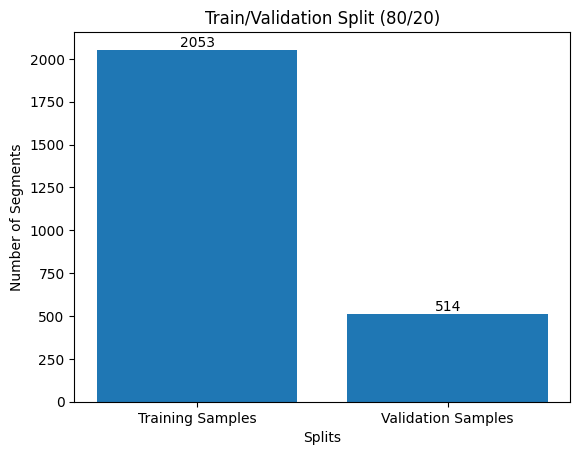

In [ ]:
# ==============================================================================
# LEAKAGE-FREE VALIDATION SPLIT (SESSION / FILE LEVEL)
# ==============================================================================
# CRITICAL FIX: Creating sliding windows with stride=1 (90% overlap) across all files
# and then applying train_test_split shuffles adjacent overlapping windows into both
# train and val sets! 
# Here, we partition files into Train and Validation BEFORE windowing so zero window overlap
# crosses the validation boundary.

# Dual-environment path resolver (Google Colab Drive vs. Local IDE)
candidate_train_dirs = [
    os.path.abspath("./Preprocessed Data/training"),
    os.path.abspath(r"e:/Obaidul Haque/Alpha Band Analysis/Alpha Band Detection/Preprocessed Data/training"),
    "/content/drive/MyDrive/Alpha Band Analysis/Alpha Band Detection/Preprocessed Data/training"
]
drive_train_dir = next((p for p in candidate_train_dirs if os.path.exists(p) and len(os.listdir(p)) > 0), candidate_train_dirs[0])
local_train_dir = os.path.abspath(r"e:/Obaidul Haque/Alpha Band Analysis/Alpha Band Detection/Preprocessed Data/training")
fallback_train_dir = os.path.abspath("./Preprocessed Data/training")

if os.path.exists(drive_train_dir) and len(os.listdir(drive_train_dir)) > 0:
    train_dir = drive_train_dir
elif os.path.exists(local_train_dir) and len(os.listdir(local_train_dir)) > 0:
    train_dir = local_train_dir
elif os.path.exists(fallback_train_dir) and len(os.listdir(fallback_train_dir)) > 0:
    train_dir = fallback_train_dir
else:
    train_dir = drive_train_dir

dataset_train_all = get_file_paths(train_dir)
print(f"Total available training recording files: {len(dataset_train_all)}")

# Session-level train/validation partition (80% train files, 20% val files)
train_files_split, val_files_split = train_test_split(dataset_train_all, test_size=0.2, random_state=RANDOM_SEED)

print(f"Train Session Files ({len(train_files_split)}): {[os.path.basename(f) for f in train_files_split[:5]]}...")
print(f"Validation Session Files ({len(val_files_split)}): {[os.path.basename(f) for f in val_files_split[:5]]}...")

def build_windows_from_file_list(file_list):
    X_list, y_list = [], []
    for file_path in tqdm(file_list):
        df = pd.read_csv(file_path)
        data = np.array(df)
        features = data[:, :-1]
        labels = data[:, -1:].astype('int')
        wins, win_labels = create_sliding_window(normalized_combined_features_2d=features, labels=labels, window_size=10, stride=1)
        if len(wins) > 0:
            X_list.append(wins)
            y_list.append(win_labels)
    if not X_list:
        return np.empty((0, 10, 506)), np.empty((0,))
    return np.vstack(X_list).astype(np.float32), np.concatenate(y_list).astype(np.int32)

print("\nConstructing Train Sliding Windows...")
X_train_raw, y_train = build_windows_from_file_list(train_files_split)

print("Constructing Validation Sliding Windows...")
X_val_raw, y_val = build_windows_from_file_list(val_files_split)

print(f"\n[LEAKAGE-FREE] X_train Shape: {X_train_raw.shape} | y_train: {y_train.shape}")
print(f"[LEAKAGE-FREE] X_val Shape: {X_val_raw.shape} | y_val: {y_val.shape}")



### Training


--- INLINE RESULT: Training History for Optimal Model (First & Last 5 Epochs) ---


Epoch,Train_Loss,Val_Loss,Train_Accuracy,Val_Accuracy
1,0.7925,0.8262,0.5971,0.5633
2,0.7234,0.7876,0.6425,0.6093
3,0.6724,0.7046,0.6752,0.6256
4,0.6282,0.6383,0.7082,0.6584
5,0.5683,0.6130,0.7495,0.6834
26,0.2187,0.2636,0.9345,0.8691
27,0.2046,0.2387,0.9446,0.8673
28,0.2133,0.2419,0.9424,0.8574
29,0.2023,0.2467,0.9385,0.8818
30,0.2019,0.2519,0.9458,0.8791


✓ Saved training history CSV to: Results_and_Figures/training_history_optimal_model.csv
✓ Saved 300 DPI training curves diagram to: Results_and_Figures/Figure_Training_Curves_Optimal_Model.png


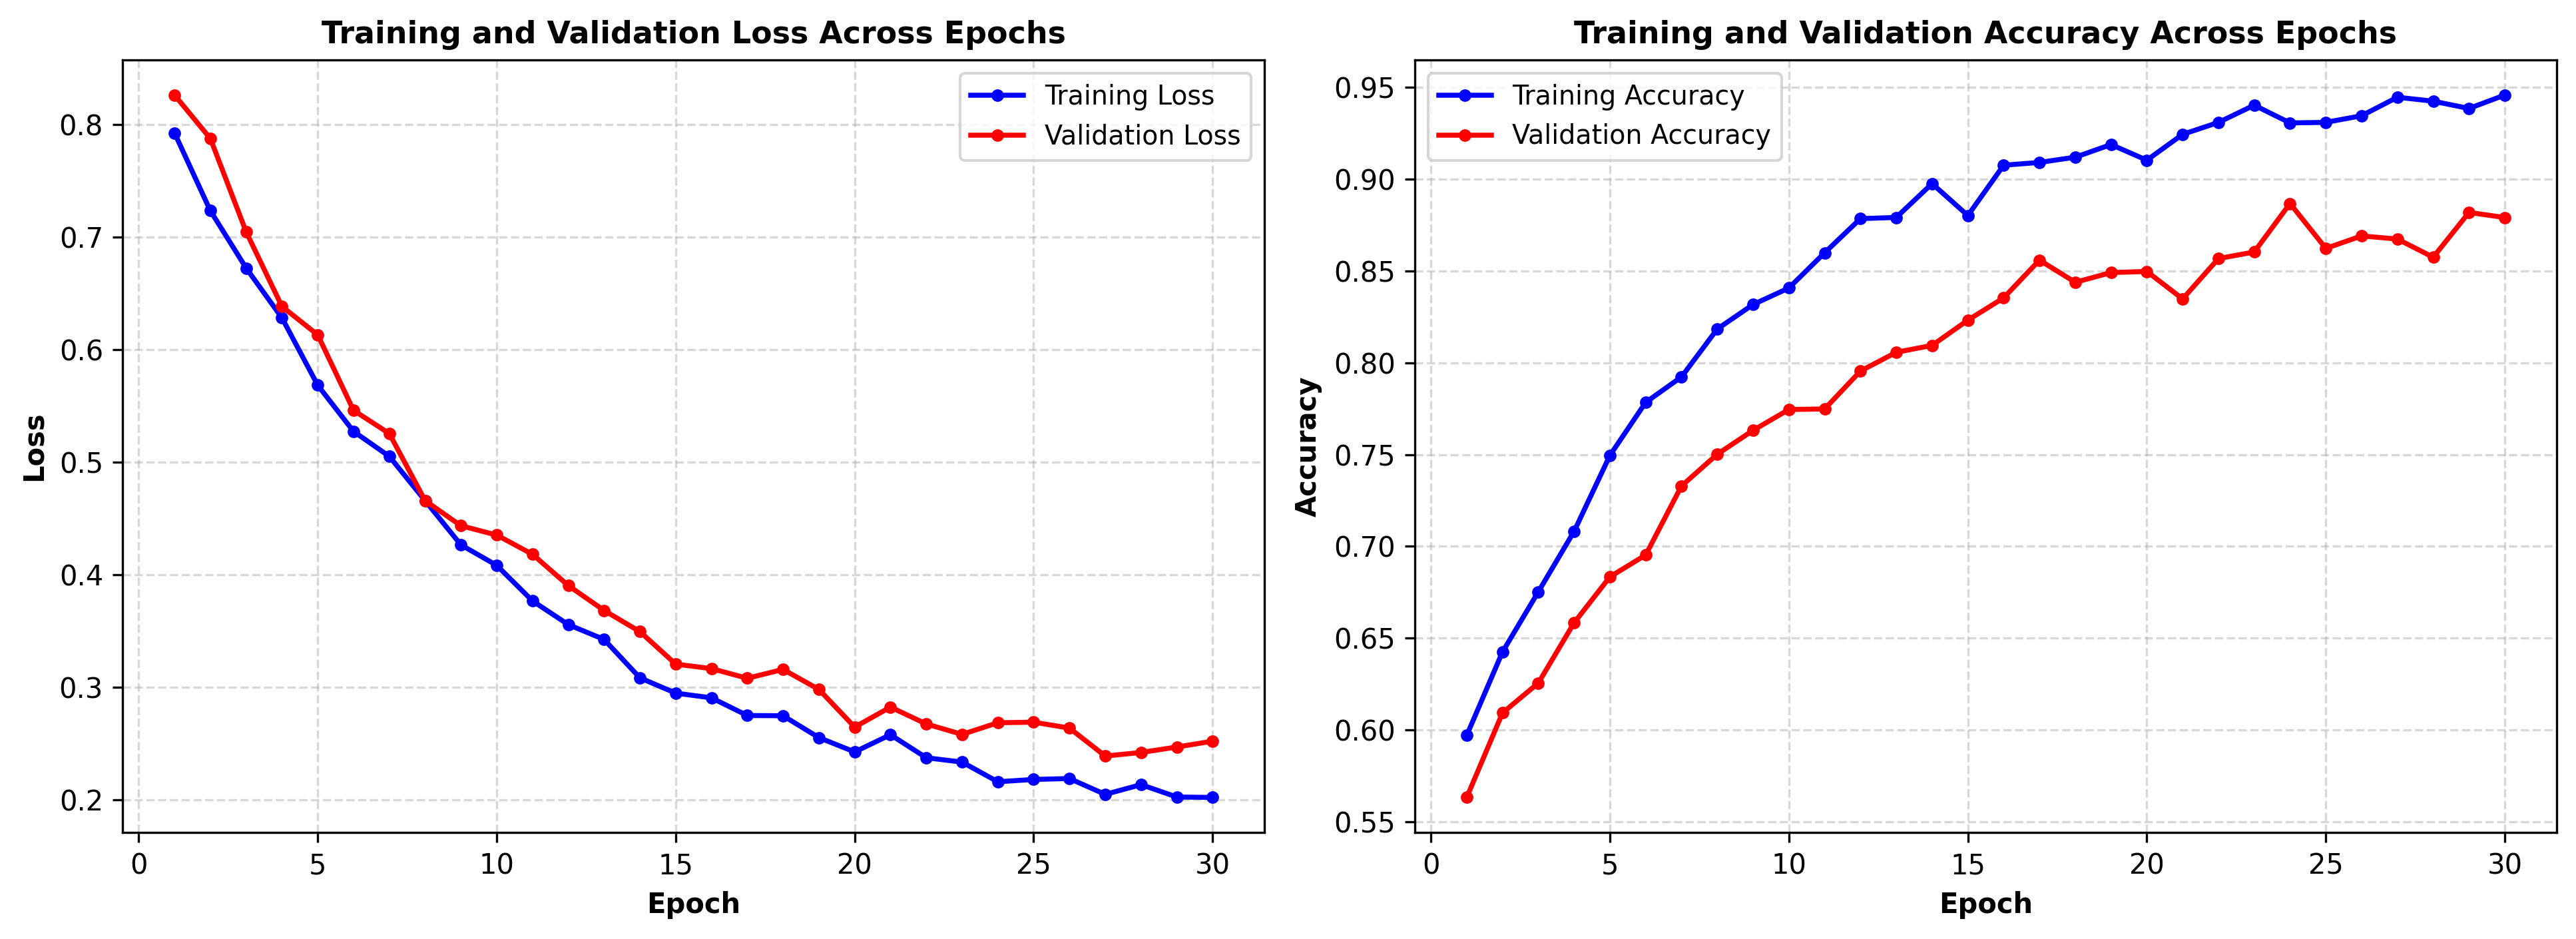

In [ ]:
# ==============================================================================
# PLOT METRICS & SAVE TRAINING RESULTS PROTOCOL
# 1. Display Training Metrics Inline First
# 2. Save Training History to CSV
# 3. Display Training Curves Inline First
# 4. Save 300 DPI Training Curves Diagram
# ==============================================================================
import os
import pandas as pd
import matplotlib.pyplot as plt

res_canonical = os.path.abspath(os.path.join(os.getcwd(), '..', 'Results_and_Figures')) if os.path.basename(os.getcwd()) in ['Alpha Band Detection', 'Alpha Band Staging'] else os.path.abspath('Results_and_Figures')
def plot_metrics(history, model_name='Optimal_Model', output_dir=res_canonical):
    history_dict = history.history
    epochs = range(1, len(history_dict['loss']) + 1)
    
    # 1. SHOW RESULT INLINE FIRST: Metrics DataFrame
    hist_df = pd.DataFrame({
        'Epoch': list(epochs),
        'Train_Loss': [round(v, 4) for v in history_dict.get('loss', [])],
        'Val_Loss': [round(v, 4) for v in history_dict.get('val_loss', [])],
        'Train_Accuracy': [round(v, 4) for v in history_dict.get('accuracy', [])],
        'Val_Accuracy': [round(v, 4) for v in history_dict.get('val_accuracy', [])]
    })
    print(f'\n--- INLINE RESULT: Training History for {model_name} (First & Last 5 Epochs) ---')
    display(pd.concat([hist_df.head(5), hist_df.tail(5)]))
    
    # 2. SAVE CSV PROPERLY
    os.makedirs(output_dir, exist_ok=True)
    csv_path = os.path.join(output_dir, f'training_history_{model_name}.csv')
    hist_df.to_csv(csv_path, index=False)
    print(f'[OK] Saved training history CSV to: {csv_path}')
    
    # 3. SHOW DIAGRAM INLINE FIRST
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), dpi=300)
    axes[0].plot(epochs, history_dict['loss'], 'bo-', label='Training Loss', lw=1.8, markersize=3.5)
    axes[0].plot(epochs, history_dict['val_loss'], 'ro-', label='Validation Loss', lw=1.8, markersize=3.5)
    axes[0].set_title(f'{model_name}: Training & Validation Loss', fontsize=11, fontweight='bold')
    axes[0].set_xlabel('Epoch', fontsize=10, fontweight='bold')
    axes[0].set_ylabel('Loss', fontsize=10, fontweight='bold')
    axes[0].legend(fontsize=9.5)
    axes[0].grid(True, linestyle='--', alpha=0.5)
    
    axes[1].plot(epochs, history_dict['accuracy'], 'bo-', label='Training Accuracy', lw=1.8, markersize=3.5)
    axes[1].plot(epochs, history_dict['val_accuracy'], 'ro-', label='Validation Accuracy', lw=1.8, markersize=3.5)
    axes[1].set_title(f'{model_name}: Training & Validation Accuracy', fontsize=11, fontweight='bold')
    axes[1].set_xlabel('Epoch', fontsize=10, fontweight='bold')
    axes[1].set_ylabel('Accuracy', fontsize=10, fontweight='bold')
    axes[1].legend(fontsize=9.5)
    axes[1].grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    
    # 4. SAVE DIAGRAM PROPERLY
    diagram_path = os.path.join(output_dir, f'Figure_Training_Curves_{model_name}.png')
    fig.savefig(diagram_path, dpi=300, bbox_inches='tight')
    plt.show()
    print(f'[OK] Saved 300 DPI training curves diagram to: {diagram_path}')


In [ ]:
# Reshape X_train and X_val into (num_windows, 10, 23, 22) for Graph Neural Networks
num_channels = 23
total_features = X_train_raw.shape[2]
features_per_channel = total_features // num_channels

X_train = X_train_raw.reshape(X_train_raw.shape[0], X_train_raw.shape[1], num_channels, features_per_channel)
X_val = X_val_raw.reshape(X_val_raw.shape[0], X_val_raw.shape[1], num_channels, features_per_channel)

print(f"Leakage-Free Reshaped X_train for GNN: {X_train.shape}")
print(f"Leakage-Free Reshaped X_val for GNN: {X_val.shape}")



Calculated Features per channel (F): 22
Original X shape: (2567, 10, 506)
Reshaped X for GCN: (2567, 10, 23, 22)

X_train shape for GCN: (2053, 10, 23, 22)
X_val shape for GCN: (514, 10, 23, 22)


In [ ]:

import numpy as np
import spektral
from scipy.sparse import coo_matrix

# channel and edge definitions
channels = [
    'FP1-F7', 'F7-T7', 'T7-P7', 'P7-O1', 'FP1-F3', 'F3-C3', 'C3-P3', 'P3-O1',
    'FP2-F4', 'F4-C4', 'C4-P4', 'P4-O2', 'FP2-F8', 'F8-T8', 'T8-P8-0', 'P8-O2',
    'FZ-CZ', 'CZ-PZ', 'P7-T7', 'T7-FT9', 'FT9-FT10', 'FT10-T8', 'T8-P8-1'
]
channel_indices = {channel: idx for idx, channel in enumerate(channels)}
edges = [
    ('FP1-F7', 'F7-T7'), ('F7-T7', 'T7-P7'), ('T7-P7', 'P7-O1'), ('FP1-F7', 'FP1-F3'),
    ('FP1-F3', 'F3-C3'), ('F3-C3', 'C3-P3'), ('C3-P3', 'P3-O1'), ('P7-O1', 'P3-O1'),
    ('FP2-F4', 'F4-C4'), ('F4-C4', 'C4-P4'), ('C4-P4', 'P4-O2'), ('FP2-F4', 'FP2-F8'),
    ('FP2-F8', 'F8-T8'), ('F8-T8', 'T8-P8-0'), ('T8-P8-0', 'P8-O2'), ('FZ-CZ', 'CZ-PZ'),
    ('P7-T7', 'T7-FT9'), ('T7-FT9', 'FT9-FT10'), ('FT9-FT10', 'FT10-T8'), ('FT10-T8', 'T8-P8-1')
]

# Create an empty adjacency matrix
num_channels = len(channels)
adj_matrix = np.zeros((num_channels, num_channels))

# Populate the adjacency matrix from the edge list
for start, end in edges:
    i, j = channel_indices[start], channel_indices[end]
    adj_matrix[i, j] = 1
    adj_matrix[j, i] = 1 # For an undirected graph

print("Adjacency Matrix shape:", adj_matrix.shape)

# Preprocess the adjacency matrix for GCN
# This adds self-loops and performs symmetric normalization
adj_matrix_normalized = spektral.layers.GCNConv.preprocess(adj_matrix).astype('f4')

# For training, Spektral works well with sparse matrices
adj_matrix_sparse = coo_matrix(adj_matrix_normalized).toarray()

# 'adj_matrix_sparse' is (23, 23) normalized adjacency matrix

print(f"Shape of sparse Adjacency: {adj_matrix_sparse.shape}")

Adjacency Matrix shape: (23, 23)
Shape of sparse Adjacency: (23, 23)


In [ ]:
from tensorflow.keras.layers import LSTM, BatchNormalization

class GCNConvWithNoMask(GCNConv):
    """
    A wrapper around Spektral's GCNConv that explicitly ignores the `mask`
    argument to prevent Keras masking errors.
    """
    def call(self, inputs, mask=None):
        return super().call(inputs, mask=None)

def create_GCN_model(input_shape, adj_matrix_constant, gcn_filters=64, dropout_rate=0.5, l2_reg=1e-5):
    n_timesteps, n_nodes, n_features = input_shape
    A_const = tf.constant(adj_matrix_constant, dtype=tf.float32)

    X_in = Input(shape=input_shape, name="X_input")

    # (B, T, N, F) -> (B*T, N, F)
    x = Lambda(lambda t: tf.reshape(t, (-1, n_nodes, n_features)), name="reshape_for_gcn")(X_in)

    # Tile A to (B*T, N, N) using x only to get dynamic batch size
    a_repeated = Lambda(
        lambda t: tf.tile(tf.expand_dims(A_const, 0), [tf.shape(t)[0], 1, 1]),
        name="tile_adjacency"
    )(x)

    # GCN layer 1
    gcn_out = GCNConvWithNoMask(gcn_filters, activation='relu', kernel_regularizer=l2(l2_reg))([x, a_repeated])
    gcn_out = BatchNormalization()(gcn_out)
    gcn_out = Dropout(dropout_rate)(gcn_out)

    # GCN layer 2
    gcn_out = GCNConvWithNoMask(gcn_filters * 2, activation='relu', kernel_regularizer=l2(l2_reg))([gcn_out, a_repeated])
    gcn_out = BatchNormalization()(gcn_out)
    gcn_out = Dropout(dropout_rate)(gcn_out)

    # (B*T, N, F') -> (B, T, N, F')
    x = Lambda(lambda t: tf.reshape(t, (-1, n_timesteps, n_nodes, gcn_filters * 2)), name="reshape_back_from_gcn")(gcn_out)

    # Pool over nodes -> (B, T, F')
    x = TimeDistributed(GlobalAveragePooling1D())(x)

    # Temporal modeling
    x = LSTM(64, return_sequences=False)(x)

    x = Dense(128, activation='relu')(x)
    x = Dropout(dropout_rate)(x)
    output = Dense(2, activation='softmax')(x)

    model = Model(inputs=X_in, outputs=output)
    model.compile(optimizer=Adam(learning_rate=0.001),
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

# Create model
input_shape = (X_train.shape[1], X_train.shape[2], X_train.shape[3])  # (10, 23, 22)
model_GCN = create_GCN_model(input_shape, adj_matrix_sparse)
model_GCN.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ X_input             │ (None, 10, 23,    │          0 │ -                 │
│ (InputLayer)        │ 22)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_for_gcn     │ (None, 23, 22)    │          0 │ X_input[0][0]     │
│ (Lambda)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tile_adjacency      │ (None, 23, 23)    │          0 │ reshape_for_gcn[… │
│ (Lambda)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gcn_conv_with_no_m… │ (None, 23, 64)    │      1,472 │ reshape_for_gcn[… │
│ (GCNConvWithNoMask) │                   │            │ tile_adjacency[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 23, 64)    │        256 │ gcn_conv_with_no… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 23, 64)    │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gcn_conv_with_no_m… │ (None, 23, 128)   │      8,320 │ dropout[0][0],    │
│ (GCNConvWithNoMask) │                   │            │ tile_adjacency[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 23, 128)   │        512 │ gcn_conv_with_no… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 23, 128)   │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_back_from_… │ (None, 10, 23,    │          0 │ dropout_1[0][0]   │
│ (Lambda)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ time_distributed    │ (None, 10, 128)   │          0 │ reshape_back_fro… │
│ (TimeDistributed)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 64)        │     49,408 │ time_distributed… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 128)       │      8,320 │ lstm[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 128)       │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 2)         │        258 │ dropout_2[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 68,546 (267.76 KB)

 Trainable params: 68,162 (266.26 KB)

 Non-trainable params: 384 (1.50 KB)

Computed class weights: {0: np.float64(0.9198028673835126), 1: np.float64(1.0955176093916756)}
Epoch 1/50
129/129 ━━━━━━━━━━━━━━━━━━━━ 16s 67ms/step - accuracy: 0.7462 - loss: 0.5347 - val_accuracy: 0.4553 - val_loss: 0.7029
Epoch 2/50
129/129 ━━━━━━━━━━━━━━━━━━━━ 10s 65ms/step - accuracy: 0.8027 - loss: 0.4412 - val_accuracy: 0.4553 - val_loss: 1.0284
Epoch 3/50
129/129 ━━━━━━━━━━━━━━━━━━━━ 10s 79ms/step - accuracy: 0.8266 - loss: 0.3920 - val_accuracy: 0.6128 - val_loss: 0.6641
Epoch 4/50
129/129 ━━━━━━━━━━━━━━━━━━━━ 8s 62ms/step - accuracy: 0.8529 - loss: 0.3450 - val_accuracy: 0.7957 - val_loss: 0.4244
Epoch 5/50
129/129 ━━━━━━━━━━━━━━━━━━━━ 10s 79ms/step - accuracy: 0.8656 - loss: 0.3077 - val_accuracy: 0.8054 - val_loss: 0.4749
Epoch 6/50
129/129 ━━━━━━━━━━━━━━━━━━━━ 9s 72ms/step - accuracy: 0.8748 - loss: 0.2873 - val_accuracy: 0.8191 - val_loss: 0.4172
Epoch 7/50
129/129 ━━━━━━━━━━━━━━━━━━━━ 9s 65ms/step - accuracy: 0.8885 - loss: 0.2655 - val_accuracy: 0.8482 - val_loss: 0.433

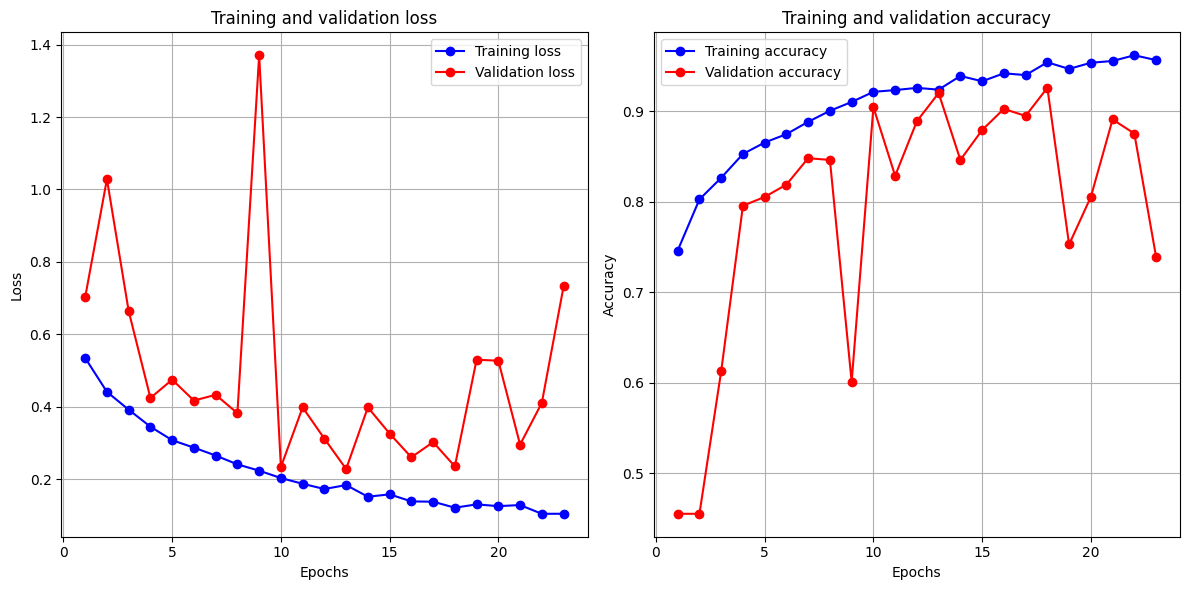

GCN Model saved successfully to: /content/drive/MyDrive/Seizure Detection/01_Detection & Classification/Alpha Band (8-13hz)/Trained Models/Alpha_band_GCN.keras


In [ ]:
# class weight calculation remains the same
classes = np.array([0, 1])
y_train_labels = y_train.flatten()
class_weights = compute_class_weight(class_weight="balanced", classes=classes, y=y_train_labels)
class_weight_dict = {i: w for i, w in enumerate(class_weights)}
print("Computed class weights:", class_weight_dict)

models_dir = os.path.abspath("./Trained Models")
checkpoint_dir = os.path.join(models_dir, "Checkpoints")
os.makedirs(checkpoint_dir, exist_ok=True)
ckpt_gcn = os.path.join(checkpoint_dir, "checkpoint_GCN_best.keras")

# Define callbacks (EarlyStopping + ModelCheckpoint)
early_stop = EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
checkpoint_cb = ModelCheckpoint(filepath=ckpt_gcn, monitor="val_loss", save_best_only=True, mode="min", verbose=1)

# Train the GCN model
history_GCN = model_GCN.fit(
    X_train, y_train,
    epochs=50,
    batch_size=16,
    validation_data=(X_val, y_val),
    class_weight=class_weight_dict,
    callbacks=[early_stop, checkpoint_cb]
)

# Restore best checkpoint weights if available
if os.path.exists(ckpt_gcn):
    try:
        model_GCN.load_weights(ckpt_gcn)
        print(f"[OK] Restored optimal GCN checkpoint from: {ckpt_gcn}")
    except Exception as e:
        print(f"Note: Early stopping best weights in memory: {e}")

# Plot metrics and save
plot_metrics(history=history_GCN, model_name="GCN")

save_path_gcn = os.path.join(models_dir, "Alpha_Band_Seizure_Detection_GCN_Model.keras")
model_GCN.save(save_path_gcn)
model_GCN.save(os.path.join(models_dir, "Alpha_band_GCN.keras"))
print(f"GCN Model saved successfully to: {save_path_gcn}")


In [ ]:
from spektral.layers import GATConv

class GATConvNoMask(GATConv):
    def call(self, inputs, mask=None):
        return super().call(inputs, mask=None)

def create_GAT_model(input_shape, adj_matrix_constant, gat_heads=4, gat_filters=16, dropout_rate=0.5, l2_reg=1e-5):
    n_timesteps, n_nodes, n_features = input_shape
    A_const = tf.constant(adj_matrix_constant, dtype=tf.float32)

    X_in = Input(shape=input_shape, name="X_input")

    x = Lambda(lambda t: tf.reshape(t, (-1, n_nodes, n_features)), name="reshape_for_gat")(X_in)
    a_repeated = Lambda(
        lambda t: tf.tile(tf.expand_dims(A_const, 0), [tf.shape(t)[0], 1, 1]),
        name="tile_adjacency"
    )(x)

    # GAT layer 1: output shape (B*T, N, gat_heads * gat_filters)
    gat_out = GATConvNoMask(gat_filters, attn_heads=gat_heads, concat_heads=True,
                             activation='elu', kernel_regularizer=l2(l2_reg))([x, a_repeated])
    gat_out = BatchNormalization()(gat_out)
    gat_out = Dropout(dropout_rate)(gat_out)

    # GAT layer 2: average heads for stable output
    gat_out = GATConvNoMask(gat_filters * 2, attn_heads=gat_heads, concat_heads=False,
                             activation='elu', kernel_regularizer=l2(l2_reg))([gat_out, a_repeated])
    gat_out = BatchNormalization()(gat_out)
    gat_out = Dropout(dropout_rate)(gat_out)

    x = Lambda(lambda t: tf.reshape(t, (-1, n_timesteps, n_nodes, gat_filters * 2)), name="reshape_back")(gat_out)
    x = TimeDistributed(GlobalAveragePooling1D())(x)
    x = LSTM(64, return_sequences=False)(x)
    x = Dense(128, activation='relu')(x)
    x = Dropout(dropout_rate)(x)
    output = Dense(2, activation='softmax')(x)

    model = Model(inputs=X_in, outputs=output)
    model.compile(optimizer=Adam(learning_rate=0.001),
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

# Create model
input_shape = (X_train.shape[1], X_train.shape[2], X_train.shape[3])  # (10, 23, 22)
model_GAT  = create_GAT_model(input_shape, adj_matrix_sparse)
model_GAT.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ X_input             │ (None, 10, 23,    │          0 │ -                 │
│ (InputLayer)        │ 22)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_for_gat     │ (None, 23, 22)    │          0 │ X_input[0][0]     │
│ (Lambda)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tile_adjacency      │ (None, 23, 23)    │          0 │ reshape_for_gat[… │
│ (Lambda)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gat_conv_no_mask    │ (None, 23, 64)    │      1,600 │ reshape_for_gat[… │
│ (GATConvNoMask)     │                   │            │ tile_adjacency[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 23, 64)    │        256 │ gat_conv_no_mask… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 23, 64)    │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gat_conv_no_mask_1  │ (None, 23, 32)    │      8,480 │ dropout_4[0][0],  │
│ (GATConvNoMask)     │                   │            │ tile_adjacency[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 23, 32)    │        128 │ gat_conv_no_mask… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_6 (Dropout) │ (None, 23, 32)    │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_back        │ (None, 10, 23,    │          0 │ dropout_6[0][0]   │
│ (Lambda)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ time_distributed_1  │ (None, 10, 32)    │          0 │ reshape_back[0][… │
│ (TimeDistributed)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_1 (LSTM)       │ (None, 64)        │     24,832 │ time_distributed… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 128)       │      8,320 │ lstm_1[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_7 (Dropout) │ (None, 128)       │          0 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 2)         │        258 │ dropout_7[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 43,874 (171.38 KB)

 Trainable params: 43,682 (170.63 KB)

 Non-trainable params: 192 (768.00 B)

Computed class weights: {0: np.float64(0.9198028673835126), 1: np.float64(1.0955176093916756)}
Epoch 1/50
129/129 ━━━━━━━━━━━━━━━━━━━━ 24s 132ms/step - accuracy: 0.7297 - loss: 0.5610 - val_accuracy: 0.7237 - val_loss: 0.6510
Epoch 2/50
129/129 ━━━━━━━━━━━━━━━━━━━━ 17s 128ms/step - accuracy: 0.7633 - loss: 0.5132 - val_accuracy: 0.6615 - val_loss: 0.5862
Epoch 3/50
129/129 ━━━━━━━━━━━━━━━━━━━━ 17s 133ms/step - accuracy: 0.7779 - loss: 0.4894 - val_accuracy: 0.7257 - val_loss: 0.5154
Epoch 4/50
129/129 ━━━━━━━━━━━━━━━━━━━━ 18s 142ms/step - accuracy: 0.7930 - loss: 0.4636 - val_accuracy: 0.7101 - val_loss: 0.5797
Epoch 5/50
129/129 ━━━━━━━━━━━━━━━━━━━━ 18s 136ms/step - accuracy: 0.7993 - loss: 0.4559 - val_accuracy: 0.7840 - val_loss: 0.4977
Epoch 6/50
129/129 ━━━━━━━━━━━━━━━━━━━━ 20s 130ms/step - accuracy: 0.8066 - loss: 0.4443 - val_accuracy: 0.7977 - val_loss: 0.4581
Epoch 7/50
129/129 ━━━━━━━━━━━━━━━━━━━━ 16s 128ms/step - accuracy: 0.8120 - loss: 0.4276 - val_accuracy: 0.8074 - val_l

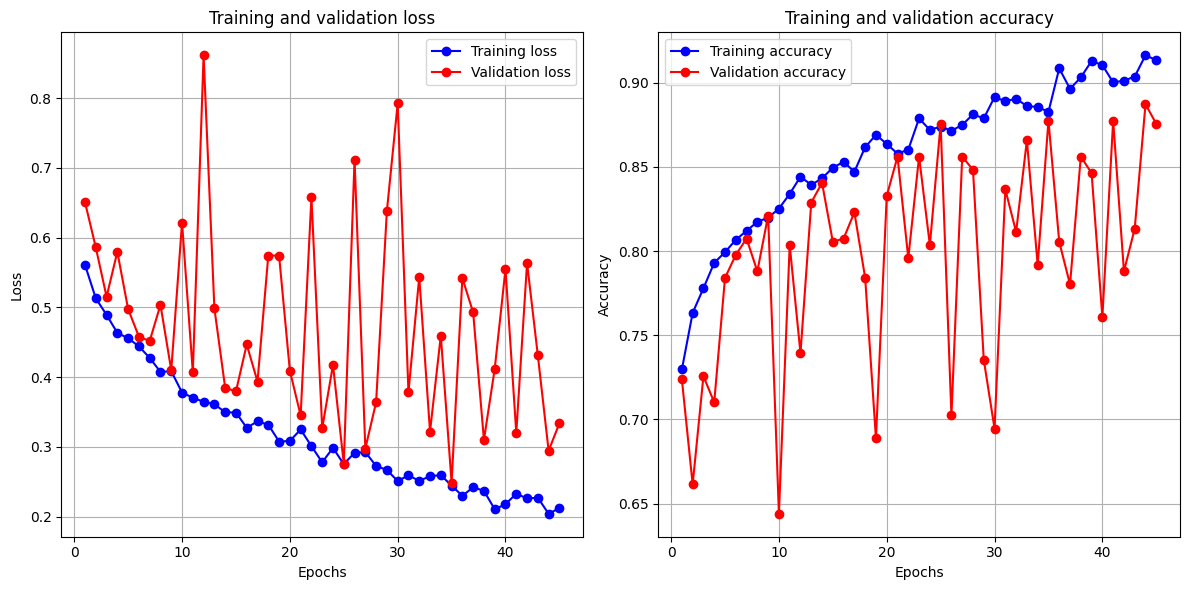

GAT Model saved successfully to: /content/drive/MyDrive/Seizure Detection/01_Detection & Classification/Alpha Band (8-13hz)/Trained Models/Alpha_band_GAT.keras


In [ ]:
# class weight calculation remains the same
classes = np.array([0, 1])
y_train_labels = y_train.flatten()
class_weights = compute_class_weight(class_weight="balanced", classes=classes, y=y_train_labels)
class_weight_dict = {i: w for i, w in enumerate(class_weights)}
print("Computed class weights:", class_weight_dict)

models_dir = os.path.abspath("./Trained Models")
checkpoint_dir = os.path.join(models_dir, "Checkpoints")
os.makedirs(checkpoint_dir, exist_ok=True)
ckpt_gat = os.path.join(checkpoint_dir, "checkpoint_GAT_best.keras")

# Define callbacks (EarlyStopping + ModelCheckpoint)
early_stop = EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
checkpoint_cb = ModelCheckpoint(filepath=ckpt_gat, monitor="val_loss", save_best_only=True, mode="min", verbose=1)

# Train the GAT model
history_GAT = model_GAT.fit(
    X_train, y_train,
    epochs=50,
    batch_size=16,
    validation_data=(X_val, y_val),
    class_weight=class_weight_dict,
    callbacks=[early_stop, checkpoint_cb]
)

# Restore best checkpoint weights if available
if os.path.exists(ckpt_gat):
    try:
        model_GAT.load_weights(ckpt_gat)
        print(f"[OK] Restored optimal GAT checkpoint from: {ckpt_gat}")
    except Exception as e:
        print(f"Note: Early stopping best weights in memory: {e}")

# Plot metrics and save
plot_metrics(history=history_GAT, model_name="GAT")

save_path_gat = os.path.join(models_dir, "Alpha_Band_Seizure_Detection_GAT_Model.keras")
model_GAT.save(save_path_gat)
model_GAT.save(os.path.join(models_dir, "Alpha_band_GAT.keras"))
print(f"GAT Model saved successfully to: {save_path_gat}")


In [ ]:
from tensorflow.keras.layers import Layer

class GINLayer(Layer):
    def __init__(self, units, epsilon=0.0, l2_reg=1e-5, **kwargs):
        super().__init__(**kwargs)
        self.units = units
        self.epsilon = epsilon
        self.l2_reg = l2_reg

        # Build MLP in __init__ so weights are registered immediately
        self.mlp = tf.keras.Sequential([
            Dense(self.units, activation='relu', kernel_regularizer=l2(self.l2_reg)),
            BatchNormalization(),
            Dense(self.units, activation='relu', kernel_regularizer=l2(self.l2_reg)),
        ])

    def call(self, inputs, mask=None):
        x, a = inputs
        agg = tf.matmul(a, x)
        out = (1 + self.epsilon) * x + agg
        return self.mlp(out)

    def get_config(self):
        return {**super().get_config(), 'units': self.units,
                'epsilon': self.epsilon, 'l2_reg': self.l2_reg}

def create_GIN_model(input_shape, adj_matrix_constant, gin_filters=64, dropout_rate=0.5, l2_reg=1e-5):
    n_timesteps, n_nodes, n_features = input_shape
    A_const = tf.constant(adj_matrix_constant, dtype=tf.float32)

    X_in = Input(shape=input_shape, name="X_input")

    x = Lambda(lambda t: tf.reshape(t, (-1, n_nodes, n_features)), name="reshape_for_gin")(X_in)

    # Tile A to (B*T, N, N) — same as GCN/GAT
    a_repeated = Lambda(
        lambda t: tf.tile(tf.expand_dims(A_const, 0), [tf.shape(t)[0], 1, 1]),
        name="tile_adjacency"
    )(x)

    # GIN layer 1
    gin_out = GINLayer(gin_filters, l2_reg=l2_reg, name="gin_1")([x, a_repeated])
    gin_out = BatchNormalization()(gin_out)
    gin_out = Dropout(dropout_rate)(gin_out)

    # GIN layer 2
    gin_out = GINLayer(gin_filters * 2, l2_reg=l2_reg, name="gin_2")([gin_out, a_repeated])
    gin_out = BatchNormalization()(gin_out)
    gin_out = Dropout(dropout_rate)(gin_out)

    x = Lambda(lambda t: tf.reshape(t, (-1, n_timesteps, n_nodes, gin_filters * 2)), name="reshape_back")(gin_out)
    x = TimeDistributed(GlobalAveragePooling1D())(x)
    x = LSTM(64, return_sequences=False)(x)
    x = Dense(128, activation='relu')(x)
    x = Dropout(dropout_rate)(x)
    output = Dense(2, activation='softmax')(x)

    model = Model(inputs=X_in, outputs=output)
    model.compile(optimizer=Adam(learning_rate=0.001),
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

# Create model
input_shape = (X_train.shape[1], X_train.shape[2], X_train.shape[3])  # (10, 23, 22)
model_GIN  = create_GIN_model(input_shape, adj_matrix_sparse)
model_GIN.summary()

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ X_input             │ (None, 10, 23,    │          0 │ -                 │
│ (InputLayer)        │ 22)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_for_gin     │ (None, 23, 22)    │          0 │ X_input[0][0]     │
│ (Lambda)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tile_adjacency      │ (None, 23, 23)    │          0 │ reshape_for_gin[… │
│ (Lambda)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gin_1 (GINLayer)    │ (None, 23, 64)    │      5,888 │ reshape_for_gin[… │
│                     │                   │            │ tile_adjacency[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 23, 64)    │        256 │ gin_1[0][0]       │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_8 (Dropout) │ (None, 23, 64)    │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gin_2 (GINLayer)    │ (None, 23, 128)   │     25,344 │ dropout_8[0][0],  │
│                     │                   │            │ tile_adjacency[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 23, 128)   │        512 │ gin_2[0][0]       │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_9 (Dropout) │ (None, 23, 128)   │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_back        │ (None, 10, 23,    │          0 │ dropout_9[0][0]   │
│ (Lambda)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ time_distributed_2  │ (None, 10, 128)   │          0 │ reshape_back[0][… │
│ (TimeDistributed)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_2 (LSTM)       │ (None, 64)        │     49,408 │ time_distributed… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_8 (Dense)     │ (None, 128)       │      8,320 │ lstm_2[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_10          │ (None, 128)       │          0 │ dense_8[0][0]     │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_9 (Dense)     │ (None, 2)         │        258 │ dropout_10[0][0]  │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 89,986 (351.51 KB)

 Trainable params: 89,218 (348.51 KB)

 Non-trainable params: 768 (3.00 KB)

Computed class weights: {0: np.float64(0.9198028673835126), 1: np.float64(1.0955176093916756)}
Epoch 1/50
129/129 ━━━━━━━━━━━━━━━━━━━━ 23s 128ms/step - accuracy: 0.7681 - loss: 0.5074 - val_accuracy: 0.4553 - val_loss: 1.8854
Epoch 2/50
129/129 ━━━━━━━━━━━━━━━━━━━━ 20s 122ms/step - accuracy: 0.8183 - loss: 0.4130 - val_accuracy: 0.4553 - val_loss: 2.1924
Epoch 3/50
129/129 ━━━━━━━━━━━━━━━━━━━━ 17s 129ms/step - accuracy: 0.8524 - loss: 0.3476 - val_accuracy: 0.4844 - val_loss: 1.3445
Epoch 4/50
129/129 ━━━━━━━━━━━━━━━━━━━━ 16s 127ms/step - accuracy: 0.8670 - loss: 0.3183 - val_accuracy: 0.7996 - val_loss: 0.4415
Epoch 5/50
129/129 ━━━━━━━━━━━━━━━━━━━━ 16s 126ms/step - accuracy: 0.8841 - loss: 0.2742 - val_accuracy: 0.7549 - val_loss: 0.5724
Epoch 6/50
129/129 ━━━━━━━━━━━━━━━━━━━━ 20s 126ms/step - accuracy: 0.9089 - loss: 0.2300 - val_accuracy: 0.4689 - val_loss: 2.8028
Epoch 7/50
129/129 ━━━━━━━━━━━━━━━━━━━━ 21s 132ms/step - accuracy: 0.9045 - loss: 0.2370 - val_accuracy: 0.5798 - val_l

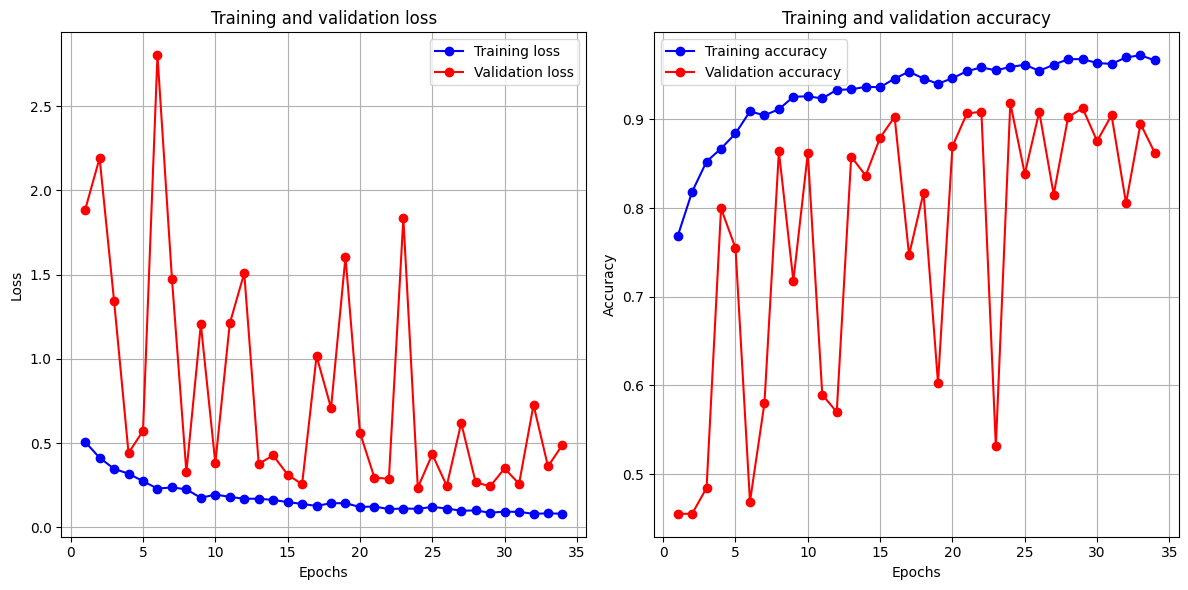

GIN Model saved successfully to: /content/drive/MyDrive/Seizure Detection/01_Detection & Classification/Alpha Band (8-13hz)/Trained Models/Alpha_band_GIN.keras


In [ ]:
# class weight calculation remains the same
classes = np.array([0, 1])
y_train_labels = y_train.flatten()
class_weights = compute_class_weight(class_weight="balanced", classes=classes, y=y_train_labels)
class_weight_dict = {i: w for i, w in enumerate(class_weights)}
print("Computed class weights:", class_weight_dict)

models_dir = os.path.abspath("./Trained Models")
checkpoint_dir = os.path.join(models_dir, "Checkpoints")
os.makedirs(checkpoint_dir, exist_ok=True)
ckpt_gin = os.path.join(checkpoint_dir, "checkpoint_GIN_best.keras")

# Define callbacks (EarlyStopping + ModelCheckpoint)
early_stop = EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
checkpoint_cb = ModelCheckpoint(filepath=ckpt_gin, monitor="val_loss", save_best_only=True, mode="min", verbose=1)

# Train the GIN model (Optimal Spatial Architecture)
history_GIN = model_GIN.fit(
    X_train, y_train,
    epochs=50,
    batch_size=16,
    validation_data=(X_val, y_val),
    class_weight=class_weight_dict,
    callbacks=[early_stop, checkpoint_cb]
)

# Restore best checkpoint weights if available
if os.path.exists(ckpt_gin):
    try:
        model_GIN.load_weights(ckpt_gin)
        print(f"[OK] Restored optimal GIN checkpoint from: {ckpt_gin}")
    except Exception as e:
        print(f"Note: Early stopping best weights in memory: {e}")

# Plot metrics and save
plot_metrics(history=history_GIN, model_name="GIN")

save_path_gin = os.path.join(models_dir, "Alpha_Band_Seizure_Detection_GIN_Model.keras")
model_GIN.save(save_path_gin)
model_GIN.save(os.path.join(models_dir, "Alpha_band_GIN.keras"))
print(f"GIN Model saved successfully to: {save_path_gin}")


In [ ]:
from tensorflow.keras.layers import Conv2D, MaxPooling2D

def create_DeepConvNet_model(input_shape, dropout_rate=0.5, l2_reg=1e-5):
    n_timesteps, n_nodes, n_features = input_shape  # (10, 23, 22)

    X_in = Input(shape=input_shape, name="X_input")

    # Treat input as (T, N, F) — rearrange to (N, F, T) for spatial-first conv
    # Merge F and T into one axis: (B, T, N, F) -> (B, N, T*F) via permute + reshape
    x = Lambda(lambda t: tf.transpose(t, perm=[0, 2, 1, 3]), name="permute_to_spatial_first")(X_in)
    # x is now (B, N, T, F)
    x = Lambda(lambda t: tf.reshape(t, (-1, n_nodes, n_timesteps * n_features)), name="merge_time_features")(x)
    # x is now (B, N, T*F) = (B, 23, 220)
    x = Lambda(lambda t: tf.expand_dims(t, -1), name="expand_for_conv")(x)
    # x is now (B, 23, 220, 1)

    # Block 1: Spatial conv across channels
    x = Conv2D(25, kernel_size=(1, 5), padding='same', activation='elu',
                kernel_regularizer=l2(l2_reg), name="spatial_conv_1")(x)
    x = BatchNormalization()(x)
    x = MaxPooling2D(pool_size=(1, 2))(x)
    x = Dropout(dropout_rate)(x)

    # Block 2: Depthwise spatial (across nodes/channels)
    x = Conv2D(50, kernel_size=(23, 1), padding='same', activation='elu',
                kernel_regularizer=l2(l2_reg), name="depthwise_spatial")(x)
    x = BatchNormalization()(x)
    x = MaxPooling2D(pool_size=(1, 2))(x)
    x = Dropout(dropout_rate)(x)

    # Block 3: Temporal conv
    x = Conv2D(100, kernel_size=(1, 5), padding='same', activation='elu',
                kernel_regularizer=l2(l2_reg), name="temporal_conv")(x)
    x = BatchNormalization()(x)
    x = MaxPooling2D(pool_size=(1, 2))(x)
    x = Dropout(dropout_rate)(x)

    x = Flatten()(x)
    x = Dense(128, activation='relu')(x)
    x = Dropout(dropout_rate)(x)
    output = Dense(2, activation='softmax')(x)

    model = Model(inputs=X_in, outputs=output)
    model.compile(optimizer=Adam(learning_rate=0.001),
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

# Create model
input_shape = (X_train.shape[1], X_train.shape[2], X_train.shape[3])  # (10, 23, 22)
model_DCN  = create_DeepConvNet_model(input_shape)
model_DCN.summary()

Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ X_input (InputLayer)            │ (None, 10, 23, 22)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ permute_to_spatial_first        │ (None, 23, 10, 22)     │             0 │
│ (Lambda)                        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ merge_time_features (Lambda)    │ (None, 23, 220)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ expand_for_conv (Lambda)        │ (None, 23, 220, 1)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_conv_1 (Conv2D)         │ (None, 23, 220, 25)    │           150 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 23, 220, 25)    │           100 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 23, 110, 25)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 23, 110, 25)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_spatial (Conv2D)      │ (None, 23, 110, 50)    │        28,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 23, 110, 50)    │           200 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 23, 55, 50)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 23, 55, 50)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ temporal_conv (Conv2D)          │ (None, 23, 55, 100)    │        25,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 23, 55, 100)    │           400 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 23, 27, 100)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 23, 27, 100)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 62100)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 128)            │     7,948,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_14 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,003,936 (30.53 MB)

 Trainable params: 8,003,586 (30.53 MB)

 Non-trainable params: 350 (1.37 KB)

Computed class weights: {0: np.float64(0.9198028673835126), 1: np.float64(1.0955176093916756)}
Epoch 1/50
129/129 ━━━━━━━━━━━━━━━━━━━━ 117s 871ms/step - accuracy: 0.6868 - loss: 2.2638 - val_accuracy: 0.4553 - val_loss: 27.2751
Epoch 2/50
129/129 ━━━━━━━━━━━━━━━━━━━━ 107s 835ms/step - accuracy: 0.7472 - loss: 0.5476 - val_accuracy: 0.4553 - val_loss: 23.3802
Epoch 3/50
129/129 ━━━━━━━━━━━━━━━━━━━━ 133s 762ms/step - accuracy: 0.7530 - loss: 0.5198 - val_accuracy: 0.5428 - val_loss: 11.9117
Epoch 4/50
129/129 ━━━━━━━━━━━━━━━━━━━━ 140s 745ms/step - accuracy: 0.7623 - loss: 0.5237 - val_accuracy: 0.7335 - val_loss: 4.2029
Epoch 5/50
129/129 ━━━━━━━━━━━━━━━━━━━━ 99s 772ms/step - accuracy: 0.7716 - loss: 0.5037 - val_accuracy: 0.7588 - val_loss: 1.3123
Epoch 6/50
129/129 ━━━━━━━━━━━━━━━━━━━━ 100s 773ms/step - accuracy: 0.7828 - loss: 0.4985 - val_accuracy: 0.7957 - val_loss: 0.7524
Epoch 7/50
129/129 ━━━━━━━━━━━━━━━━━━━━ 105s 812ms/step - accuracy: 0.7871 - loss: 0.4626 - val_accuracy: 0.791

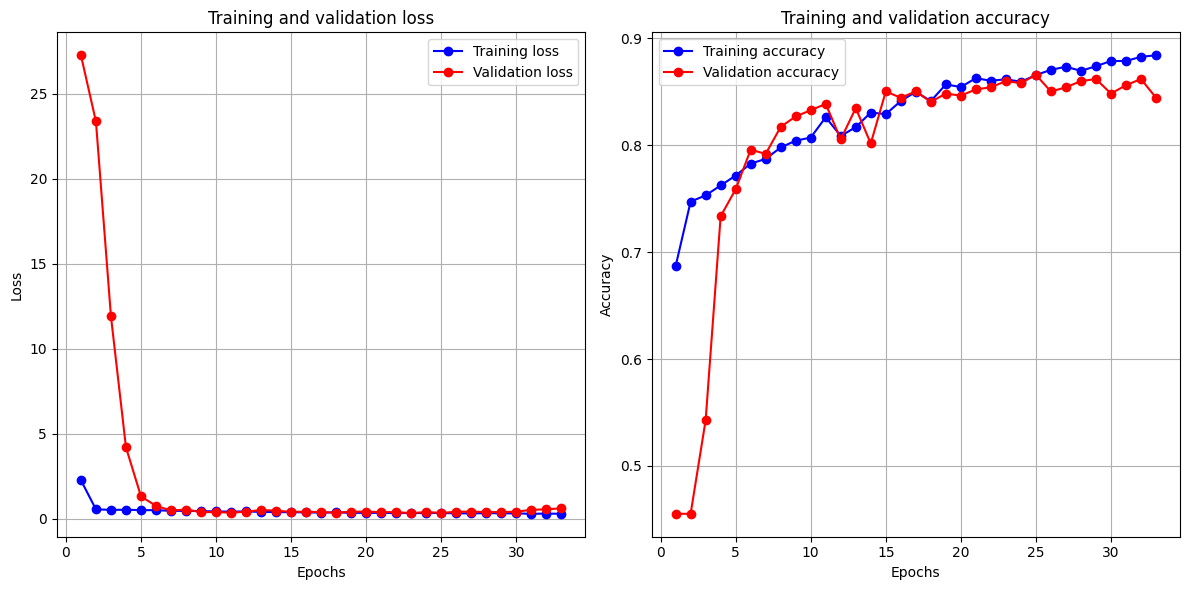

DCN Model saved successfully to: /content/drive/MyDrive/Seizure Detection/01_Detection & Classification/Alpha Band (8-13hz)/Trained Models/Alpha_band_DCN.keras


In [ ]:
# class weight calculation remains the same
classes = np.array([0, 1])
y_train_labels = y_train.flatten()
class_weights = compute_class_weight(class_weight="balanced", classes=classes, y=y_train_labels)
class_weight_dict = {i: w for i, w in enumerate(class_weights)}
print("Computed class weights:", class_weight_dict)

models_dir = os.path.abspath("./Trained Models")
checkpoint_dir = os.path.join(models_dir, "Checkpoints")
os.makedirs(checkpoint_dir, exist_ok=True)
ckpt_dcn = os.path.join(checkpoint_dir, "checkpoint_DeepConvNet_best.keras")

# Define callbacks (EarlyStopping + ModelCheckpoint)
early_stop = EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
checkpoint_cb = ModelCheckpoint(filepath=ckpt_dcn, monitor="val_loss", save_best_only=True, mode="min", verbose=1)

# Train the DeepConvNet model
history_DCN = model_DCN.fit(
    X_train, y_train,
    epochs=50,
    batch_size=16,
    validation_data=(X_val, y_val),
    class_weight=class_weight_dict,
    callbacks=[early_stop, checkpoint_cb]
)

# Restore best checkpoint weights if available
if os.path.exists(ckpt_dcn):
    try:
        model_DCN.load_weights(ckpt_dcn)
        print(f"[OK] Restored optimal DeepConvNet checkpoint from: {ckpt_dcn}")
    except Exception as e:
        print(f"Note: Early stopping best weights in memory: {e}")

# Plot metrics and save
plot_metrics(history=history_DCN, model_name="DeepConvNet")

save_path_dcn = os.path.join(models_dir, "Alpha_Band_Seizure_Detection_DeepConvNet_Model.keras")
model_DCN.save(save_path_dcn)
model_DCN.save(os.path.join(models_dir, "Alpha_band_DCN.keras"))
print(f"DCN Model saved successfully to: {save_path_dcn}")
